# 表形式 Q 学習（FrozenLake）

**出典**　機械学習 4 分野の教科書 — 第 11 章 4-A MDP と価値ベース ／ 07 実装：表形式 Q 学習から DQN の骨格まで

**このノートのパス**　`ml-code/11_mdp_q/01_tabular_q_learning.ipynb`

**このノートで確かめること**
Q テーブルを 1 行の更新式だけで学習させる。
**`reset(seed=)` を毎エピソード渡してはいけない**理由と、
**ε を減衰させる**ことで探索から活用へ移る様子を確かめる。

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `gymnasium numpy` |
| 実行時間の目安 | 約 20 秒 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [2]:
# 未導入なら実行する（Colab など）
# !pip install -q gymnasium numpy

In [3]:
import numpy as np
import gymnasium as gym

env = gym.make("FrozenLake-v1", is_slippery=False)
n_states, n_actions = env.observation_space.n, env.action_space.n

Q = np.zeros((n_states, n_actions))
alpha, gamma = 0.1, 0.99
eps, eps_min, eps_decay = 1.0, 0.02, 0.9995
rng = np.random.default_rng(42)

returns = []
for ep in range(5000):
    # seed は最初の 1 回だけ渡す。毎エピソード渡すと環境の乱数系列が毎回リセットされ、
    # 「毎回まったく同じ初期状態」になってしまう（探索の多様性が失われる）
    s, _ = env.reset(seed=42) if ep == 0 else env.reset()
    done, total = False, 0.0
    while not done:
        # --- ε-greedy で行動を選ぶ ---
        if rng.random() < eps:
            a = int(rng.integers(n_actions))          # 探索
        else:
            a = int(np.argmax(Q[s]))                  # 活用

        s2, r, terminated, truncated, _ = env.step(a)
        done = terminated or truncated
        total += r

        # --- Q 学習の更新（次状態の最大値を使う = 方策オフ型） ---
        target = r + gamma * np.max(Q[s2]) * (not terminated)
        Q[s, a] += alpha * (target - Q[s, a])
        s = s2

    returns.append(total)
    eps = max(eps_min, eps * eps_decay)

print("学習した方策:", np.argmax(Q, axis=1).reshape(4, 4))
print("最後の 500 エピソードの成功率:", np.mean(returns[-500:]))

学習した方策: [[2 2 1 0]
 [1 0 1 0]
 [2 2 1 0]
 [0 2 2 0]]
最後の 500 エピソードの成功率: 0.902


### 学習の進み方を見る — ε の減衰と成功率

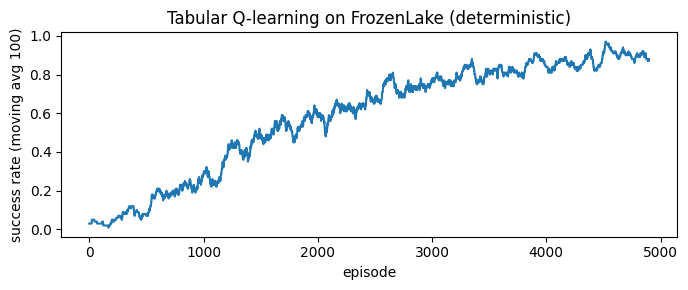

Q テーブル（各状態の最大 Q 値）:
[[0.951 0.961 0.97  0.961]
 [0.961 0.    0.98  0.   ]
 [0.97  0.98  0.99  0.   ]
 [0.    0.99  1.    0.   ]]


In [4]:
import matplotlib.pyplot as plt

w = 100
ma = np.convolve(returns, np.ones(w) / w, mode="valid")
plt.figure(figsize=(7, 3))
plt.plot(ma); plt.xlabel("episode"); plt.ylabel(f"success rate (moving avg {w})")
plt.title("Tabular Q-learning on FrozenLake (deterministic)")
plt.tight_layout(); plt.show()

print("Q テーブル（各状態の最大 Q 値）:")
print(np.round(Q.max(axis=1).reshape(4, 4), 3))

### 学習した方策で実際に歩かせてみる

In [5]:
ARROW = {0: "←", 1: "↓", 2: "→", 3: "↑"}
desc = env.unwrapped.desc.astype(str)
policy = np.argmax(Q, axis=1).reshape(4, 4)

for i in range(4):
    row = []
    for j in range(4):
        cell = desc[i][j]
        row.append(cell if cell in ("H", "G") else ARROW[policy[i, j]])
    print(" ".join(row))

# 貪欲方策で 1 エピソード走らせる
s, _ = env.reset()
path, done = [s], False
while not done:
    s, r, terminated, truncated, _ = env.step(int(np.argmax(Q[s])))
    path.append(s); done = terminated or truncated
print("\n経路:", path, "／ 報酬:", r)
env.close()

→ → ↓ ←
↓ H ↓ H
→ → ↓ H
H → → G

経路: [0, 1, 2, 6, 10, 14, 15] ／ 報酬: 1


## 読み取りどころ

- ⚠️ **`reset(seed=42)` を毎エピソード渡すと学習が壊れる。**環境の乱数系列が毎回リセットされ、同じ軌跡しか経験しなくなる。**seed は最初の 1 回だけ。**
- **`* (not terminated)` が終端の処理。**ゴールや穴に落ちた先には将来価値が無いので、ブートストラップを切る。ここを忘れると価値が無限に膨らむ。
- **`truncated` と `terminated` は別物。**`terminated` は本当の終端（穴・ゴール）、`truncated` は時間切れ。**時間切れでは将来価値を切ってはいけない**——上のコードが `terminated` だけを見ているのはそのため。
- **`max(Q[s2])` を使うので方策オフ型**である。実際に取った行動ではなく「最善を取ったとしたら」で更新する。

⚠️ `is_slippery=True` にすると確率的な環境になり、同じ設定では学習が難しくなる。**alpha を下げ、エピソード数を大きく増やす必要がある。**